In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

df = pd.read_csv('seeds_data.csv')
X = StandardScaler().fit_transform(df.drop(columns='Class'))
y = df['Class'].to_numpy()  # held out until final evaluation

,k,inertia,silhouette
0,2,659.172,0.466
1,3,430.659,0.401
2,4,371.294,0.335
3,5,326.306,0.286
4,6,290.569,0.281
5,7,263.582,0.274
6,8,240.742,0.251
7,9,222.204,0.267
8,10,205.020,0.251


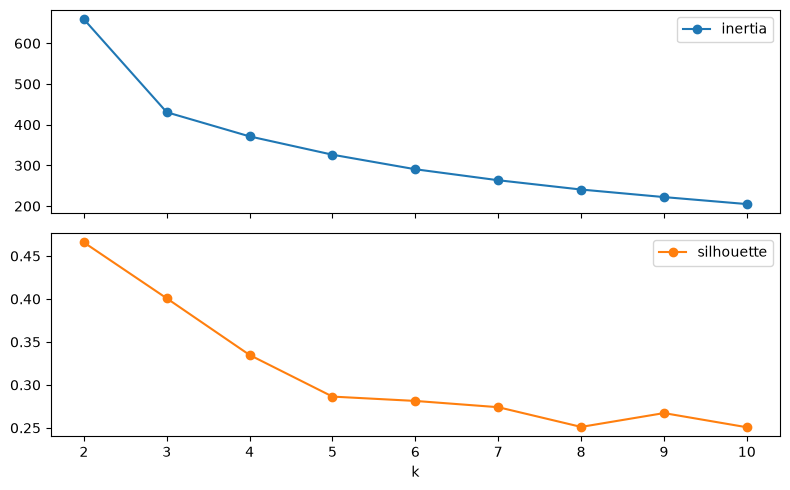

In [2]:
def kmeans(X, k, seed=0, starts=10, max_iter=100):
    rng, best = np.random.default_rng(seed), None
    for _ in range(starts):
        centers = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = ((X[:, None] - centers) ** 2).sum(axis=2).min(axis=1)
            centers.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        centers = np.array(centers)
        for _ in range(max_iter):
            labels = ((X[:, None] - centers) ** 2).sum(axis=2).argmin(axis=1)
            updated = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else X[rng.integers(len(X))] for j in range(k)])
            if np.allclose(centers, updated, atol=1e-4): break
            centers = updated
        inertia = ((X - centers[labels]) ** 2).sum()
        if best is None or inertia < best[0]: best = inertia, centers, labels
    return best

scores = []
for k_try in range(2, 11):
    inertia, centers, labels = kmeans(X, k_try)
    scores.append((k_try, inertia, silhouette_score(X, labels)))
scores = pd.DataFrame(scores, columns=['k', 'inertia', 'silhouette'])
display(scores.round(3))
scores.set_index('k')[['inertia', 'silhouette']].plot(subplots=True, marker='o', figsize=(8, 5))
plt.tight_layout(); plt.show()

# Elbow choice; silhouette is shown as a second diagnostic.
k = 3
inertia, km_centers, km_labels = kmeans(X, k, seed=42, starts=30)

In [3]:
scaler = StandardScaler().fit(df.drop(columns='Class'))
centers = pd.DataFrame(scaler.inverse_transform(km_centers), columns=df.columns[:-1])
print('K-Means centers (original units):')
display(centers.round(3))

K-Means centers (original units):


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
0,18.495,16.203,0.884,6.176,3.698,3.632,6.042
1,11.857,13.248,0.848,5.232,2.850,4.742,5.102
2,14.438,14.338,0.882,5.515,3.259,2.707,5.121


In [4]:
def dbscan(X, eps, min_samples):
    D = np.sqrt(((X[:, None] - X[None, :]) ** 2).sum(axis=2))
    neighbors = [np.flatnonzero(row <= eps).tolist() for row in D]
    labels, cluster = np.full(len(X), -99), 0
    for i in range(len(X)):
        if labels[i] != -99: continue
        if len(neighbors[i]) < min_samples:
            labels[i] = -1
            continue
        labels[i] = cluster
        queue, seen, q = list(neighbors[i]), set(neighbors[i]), 0
        while q < len(queue):
            j = queue[q]; q += 1
            if labels[j] == -99:
                labels[j] = cluster
                if len(neighbors[j]) >= min_samples:
                    for n in neighbors[j]:
                        if n not in seen: queue.append(n); seen.add(n)
            elif labels[j] == -1:
                labels[j] = cluster
        cluster += 1
    return labels

D = np.sqrt(((X[:, None] - X[None, :]) ** 2).sum(axis=2))
choices = []
for m in (4, 5, 6, 8, 10):
    kth = np.sort(D, axis=1)[:, m - 1]
    for eps_try in np.quantile(kth, np.linspace(.1, .9, 25)):
        labels = dbscan(X, eps_try, m)
        keep = labels != -1
        if len(np.unique(labels[keep])) > 1 and keep.sum() > len(np.unique(labels[keep])):
            score = silhouette_score(X[keep], labels[keep]) * keep.mean()
            choices.append((score, eps_try, m, labels))
_, eps, min_samples, db_labels = max(choices, key=lambda r: r[0])
print(f'eps={eps:.3f}, min_samples={min_samples}')
print(f"Clusters: {len(set(db_labels) - {-1})}; noise points: {(db_labels == -1).sum()}")

eps=1.096, min_samples=10
Clusters: 2; noise points: 22


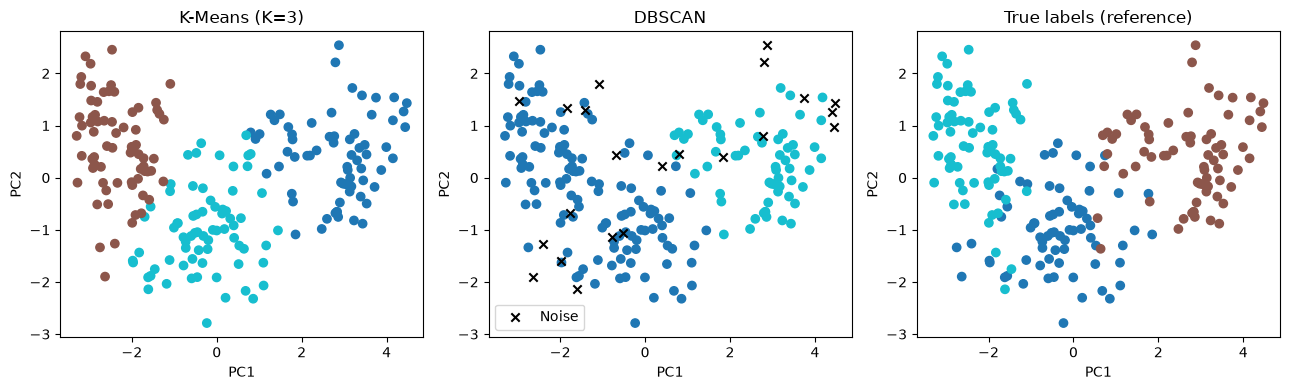

,K-Means,DBSCAN
ARI vs true class,0.773,0.412
NMI vs true class,0.728,0.452


In [5]:
Z = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].scatter(*Z.T, c=km_labels, cmap='tab10'); ax[0].set_title(f'K-Means (K={k})')
keep = db_labels != -1
ax[1].scatter(*Z[keep].T, c=db_labels[keep], cmap='tab10')
ax[1].scatter(*Z[~keep].T, c='black', marker='x', label='Noise'); ax[1].legend(); ax[1].set_title('DBSCAN')
ax[2].scatter(*Z.T, c=y, cmap='tab10'); ax[2].set_title('True labels (reference)')
for a in ax: a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout(); plt.show()

results = pd.DataFrame({name: [adjusted_rand_score(y, labels), normalized_mutual_info_score(y, labels)]
                        for name, labels in [('K-Means', km_labels), ('DBSCAN', db_labels)]},
                       index=['ARI vs true class', 'NMI vs true class'])
display(results.round(3))